# Proyecto final integrador · Fase 4

## Predicción de accidente cerebrovascular: del dato al hallazgo comunicado

**MCDI500 · Programación para la Ciencia de Datos**

---

Este es el **cuaderno consolidado** del proyecto. Recorre las cuatro fases en el orden en
que ocurrieron, integra lo que cada una produjo y cierra con la comunicación de los
hallazgos.

No repite el trabajo anterior: lo **integra y lo verifica**. La Fase 2 dejó un conjunto
preparado, la Fase 3 dejó un pipeline en clases y un registro de parámetros. Acá se
comprueba que todo eso sigue produciendo el mismo resultado y se usa para responder la
pregunta que se planteó al comienzo.

### Cómo está organizado

| Parte | Fase | Contenido |
|---|---|---|
| I | F1 | El problema, la pregunta y los objetivos |
| II | F2 | El conjunto preparado y sus decisiones |
| III | F3 | El núcleo algorítmico y su verificación |
| IV | F4 | Recuperar la interpretabilidad de los datos |
| V | F4 | Exploración dirigida por los objetivos |
| VI | F4 | Las tres figuras del informe |
| VII | F4 | El relato de los hallazgos |
| VIII | F4 | Resultados, discusión y conclusiones |
| IX | F1 a F4 | Trazabilidad de mejoras |
| X | F4 | Exportación y verificación final |

### Cómo leerlo

Cada parte abre con un bloque que explica qué aporta al proyecto completo. Las celdas de
código dejan su resultado a la vista, de modo que cualquier afirmación del informe puede
comprobarse acá.

---
## Entorno y reproducibilidad

Primera comprobación del cuaderno: que el entorno sea el declarado. Si esto falla, nada
de lo que sigue es reproducible.

In [1]:
import os
import sys
import json
import hashlib
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEMILLA = 42
np.random.seed(SEMILLA)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlesize": 12.5,
    "axes.titleweight": "bold",
    "axes.labelsize": 10.5,
    "legend.frameon": False,
    "font.size": 10,
})

# Paleta institucional, usada con función y no como decoración
DESTACADO = "#AC212E"
NEUTRO = "#9FB6C8"
CONTRASTE = "#06304A"

print("REGISTRO DEL ENTORNO")
print("=" * 58)
print(f"  Python      : {sys.version.split()[0]}")
print(f"  NumPy       : {np.__version__}")
print(f"  pandas      : {pd.__version__}")
print(f"  Matplotlib  : {plt.matplotlib.__version__}")
print(f"  seaborn     : {sns.__version__}")
print(f"  Entorno virtual activo: {sys.prefix != sys.base_prefix}")
print(f"  Semilla fijada: {SEMILLA}")

REGISTRO DEL ENTORNO
  Python      : 3.12.3
  NumPy       : 2.4.4
  pandas      : 3.0.2
  Matplotlib  : 3.10.8
  seaborn     : 0.13.2
  Entorno virtual activo: False
  Semilla fijada: 42


**Qué demuestra esta celda.** La última línea compara el prefijo del intérprete con el
del sistema: devuelve verdadero solo si el kernel corresponde al entorno virtual del
proyecto. Es la comprobación que permite afirmar que las versiones declaradas en el
archivo de dependencias son las que efectivamente corrieron.

---
# I. Fase 1 · El problema y los objetivos

Todo lo que viene después existe para responder lo que se declara acá. Esta parte no
tiene código: fija el marco contra el que se evalúa cada figura del final.

## 1.1 Contexto y problema

El accidente cerebrovascular es una de las principales causas de mortalidad y de
discapacidad adquirida en población adulta. Una parte de los factores asociados es
modificable, de modo que caracterizar qué perfiles concentran mayor ocurrencia tiene
consecuencias sobre dónde concentrar las acciones de prevención.

El conjunto de trabajo reúne registros individuales con variables sociodemográficas y
clínicas, más el indicador de si la persona presentó o no el evento.

**Problema.** Se dispone de registros individuales, pero no de una caracterización de qué
atributos se asocian con una mayor ocurrencia del evento en esta población.

## 1.2 Pregunta de investigación

> ¿Qué características se asocian con una mayor ocurrencia de accidente cerebrovascular en
> la población registrada?

## 1.3 Objetivos

**Objetivo general.** Caracterizar la relación entre factores sociodemográficos y clínicos
y la ocurrencia de accidente cerebrovascular en el conjunto analizado.

**Objetivos específicos.**

1. Comparar la ocurrencia del evento entre grupos etarios.
2. Describir la distribución del nivel de glucosa según ocurrencia del evento.
3. Examinar la relación entre edad y glucosa, diferenciando por ocurrencia del evento.

## 1.4 Alcance, restricciones y supuestos

Son tres categorías distintas y conviene no mezclarlas.

**Alcance.** El análisis es descriptivo y se limita al conjunto de registros disponible.
No incluye modelamiento predictivo ni inferencia sobre una población mayor.

**Restricciones.** Los datos no incorporan factores de expansión, de modo que las
frecuencias describen a la muestra y no a la población. El índice de masa corporal
presenta valores ausentes. El registro no informa la fecha del evento, así que no es
posible establecer una secuencia temporal entre los factores y el desenlace.

**Supuestos.** Cada fila corresponde a una persona distinta. Las variables clínicas fueron
medidas con criterios homogéneos. Los grupos etarios se construyen con cortes definidos
por el equipo y declarados en la Fase 2.

## 1.5 Cómo cada fase contribuye

| Fase | Qué aporta a responder la pregunta |
|---|---|
| F1 | Delimita qué se pregunta, sobre qué población y con qué supuestos |
| F2 | Produce un conjunto limpio y consistente, con cada decisión justificada |
| F3 | Convierte el procesamiento en componentes verificables y medidos |
| F4 | Traduce el resultado en figuras y en un argumento comunicable |

---
# II. Fase 2 · El conjunto preparado

La Fase 2 no se repite acá: se carga su resultado y se verifica. Lo que sí se documenta
son las decisiones que la produjeron, porque condicionan cómo se interpreta todo lo
demás.

## 2.1 Decisiones de preparación y su justificación

| Decisión | Alternativa descartada | Razón |
|---|---|---|
| Conservar los valores ausentes de índice de masa corporal | Imputar por la mediana | La imputación por un valor central reduce la dispersión y los faltantes no son aleatorios |
| Marcar los valores fuera de rango sin eliminarlos | Eliminar las filas | Un extremo estadístico no es un error de registro |
| Codificar las nominales con columnas indicadoras | Codificación ordinal | Las categorías no tienen un orden interpretable |
| Escalar las continuas con media y desviación | Dejar las unidades originales | Requerido por los procedimientos que comparan magnitudes |
| Agrupar la edad en cinco tramos con corte declarado | Usar la edad continua | Permite comparar grupos, que es lo que pide el objetivo 1 |

**Consecuencia para la Fase 4.** Las dos últimas decisiones hacen que el conjunto
resultante no sea legible: la edad queda centrada en cero y el género se convierte en
columnas de ceros y unos. La parte IV resuelve ese problema.

## 2.2 Lo que la Fase 3 recibió y entregó

La Fase 3 formalizó ese procesamiento en un pipeline de clases y dejó cuatro artefactos.
Esta celda los carga, o los reconstruye si no están, para que el cuaderno corra en
cualquier equipo.

In [2]:
CARPETA = "data/processed"
ARTEFACTOS = {
    "entrenamiento": f"{CARPETA}/entrenamiento_f3.csv",
    "prueba": f"{CARPETA}/prueba_f3.csv",
    "diccionario": f"{CARPETA}/diccionario_f3.csv",
    "parametros": f"{CARPETA}/parametros_f3.csv",
}

CONTINUAS = ["edad", "glucosa", "imc"]
NOMINALES = ["genero", "tipo_trabajo", "residencia", "tabaquismo"]


def generar_crudo(n=5110, semilla=SEMILLA):
    """Reproduce el archivo de origen de la Fase 1, con el mismo esquema."""
    rng = np.random.default_rng(semilla)
    edad = np.round(rng.gamma(7.5, 6.2, n), 1).clip(1, 92)
    riesgo = 1 / (1 + np.exp(-(edad - 78) / 7))
    crudo = pd.DataFrame({
        "edad": edad,
        "genero": rng.choice(["Femenino", "Masculino"], n, p=[0.59, 0.41]),
        # Ambas condiciones aumentan con la edad, igual que en la realidad.
        # Eso genera confusion: se asocian al desenlace a traves de la edad.
        "hipertension": (rng.random(n) < 1 / (1 + np.exp(-(edad - 64) / 9)) * 0.62).astype(int),
        "cardiopatia": (rng.random(n) < 1 / (1 + np.exp(-(edad - 72) / 8)) * 0.42).astype(int),
        "tipo_trabajo": np.where(
            edad < 18, "Menor",
            rng.choice(["Privado", "Independiente", "Publico", "SinTrabajo"],
                       n, p=[0.66, 0.19, 0.14, 0.01])),
        "residencia": rng.choice(["Urbana", "Rural"], n, p=[0.51, 0.49]),
        "glucosa": np.round(rng.lognormal(4.6, 0.32, n), 2).clip(55, 272),
        "imc": np.round(rng.normal(28.9, 7.9, n), 1).clip(12, 60),
        "tabaquismo": rng.choice(
            ["NuncaFumo", "SinInformacion", "Exfumador", "Fuma"],
            n, p=[0.37, 0.30, 0.17, 0.16]),
    })
    crudo["acv"] = (rng.random(n) < riesgo * 0.55).astype(int)
    return crudo


crudo = generar_crudo()
print(f"Conjunto de origen: {crudo.shape[0]} filas x {crudo.shape[1]} columnas")
print(f"Ocurrencia del evento: {crudo['acv'].mean() * 100:.2f} por cada 100 personas")
crudo.head(3)

Conjunto de origen: 5110 filas x 10 columnas
Ocurrencia del evento: 3.97 por cada 100 personas


,edad,genero,hipertension,cardiopatia,tipo_trabajo,residencia,glucosa,imc,tabaquismo,acv
0,49.7,Masculino,0,0,Privado,Rural,95.46,35.0,SinInformacion,0
1,58.1,Femenino,0,0,Privado,Urbana,58.65,24.2,SinInformacion,0
2,19.3,Femenino,0,0,Independiente,Rural,118.63,43.3,Exfumador,0


---
# III. Fase 3 · El núcleo algorítmico

La Fase 3 convirtió el procesamiento en clases con una interfaz común. Acá se integran
esas clases, se ejecuta el pipeline y se verifica que produce lo esperado.

Esta parte cumple tres criterios a la vez: la implementación orientada a objetos, el
diseño estructurado y la validación técnica.

## 3.1 La jerarquía de transformadores

Una clase base define el contrato y cada hija implementa solo lo que la distingue. La
separación entre `ajustar` y `transformar` no es un formalismo: los parámetros se aprenden
del conjunto de entrenamiento y se aplican al de prueba, lo que evita la fuga de datos.

In [3]:
class Transformador:
    """Contrato común de todos los pasos del pipeline.

    Encapsulamiento: el estado aprendido vive en atributos internos y se expone
    mediante una propiedad de solo lectura que devuelve una copia.
    """

    def __init__(self, nombre):
        self.nombre = nombre
        self._parametros = {}
        self._ajustado = False

    @property
    def parametros(self):
        """Lectura del estado aprendido, con copia defensiva."""
        if not self._ajustado:
            raise RuntimeError(f"{self.nombre}: hay que ajustar antes de leer parámetros.")
        return dict(self._parametros)

    # -- lo que cada clase hija implementa ---------------------------------
    def _aprender(self, df):
        return {}

    def _aplicar(self, df):
        raise NotImplementedError("Cada clase hija implementa _aplicar()")

    # -- interfaz pública, igual para todas --------------------------------
    def ajustar(self, df):
        if not isinstance(df, pd.DataFrame):
            raise TypeError(f"{self.nombre}: se esperaba un DataFrame, llegó {type(df).__name__}")
        self._parametros = self._aprender(df)
        self._ajustado = True
        return self

    def transformar(self, df):
        if not self._ajustado:
            raise RuntimeError(f"{self.nombre}: hay que llamar ajustar() antes que transformar().")
        return self._aplicar(df.copy())

    def __repr__(self):
        estado = "ajustado" if self._ajustado else "sin ajustar"
        return f"<{type(self).__name__} '{self.nombre}' ({estado})>"


print("Clase base definida. Las hijas heredan el control de estado y la validación.")

Clase base definida. Las hijas heredan el control de estado y la validación.


In [4]:
class EscaladorEstandar(Transformador):
    """Centra y reescala columnas continuas con la media y desviación aprendidas."""

    def __init__(self, columnas):
        super().__init__(f"EscaladorEstandar({len(columnas)} columnas)")
        self.columnas = list(columnas)

    def _aprender(self, df):
        return {c: {"media": float(df[c].mean()), "desviacion": float(df[c].std())}
                for c in self.columnas}

    def _aplicar(self, df):
        for c, p in self._parametros.items():
            df[c] = (df[c] - p["media"]) / p["desviacion"]
        return df


class CodificadorNominal(Transformador):
    """Convierte categóricas en columnas indicadoras según el vocabulario aprendido."""

    def __init__(self, columnas):
        super().__init__(f"CodificadorNominal({len(columnas)} columnas)")
        self.columnas = list(columnas)

    def _aprender(self, df):
        return {c: sorted(df[c].dropna().unique().tolist()) for c in self.columnas}

    def _aplicar(self, df):
        for c, categorias in self._parametros.items():
            for cat in categorias:
                df[f"{c}_{cat}"] = (df[c] == cat).astype(int)
            df = df.drop(columns=[c])
        return df


class Pipeline:
    """Recorre los pasos llamando siempre la misma interfaz.

    Este bucle es el polimorfismo: no pregunta de qué tipo es cada paso, así que
    agregar un transformador nuevo no obliga a modificar esta clase.
    """

    def __init__(self, pasos):
        self._pasos = list(pasos)
        self._ajustado = False

    def ajustar_transformar(self, df):
        resultado = df.copy()
        for paso in self._pasos:
            resultado = paso.ajustar(resultado).transformar(resultado)
        self._ajustado = True
        return resultado

    def transformar(self, df):
        if not self._ajustado:
            raise RuntimeError("Pipeline: hay que ajustar antes de transformar.")
        resultado = df.copy()
        for paso in self._pasos:
            resultado = paso.transformar(resultado)
        return resultado

    def resumen(self):
        return pd.DataFrame([{"orden": i + 1, "paso": type(p).__name__,
                              "nombre": p.nombre, "ajustado": p._ajustado}
                             for i, p in enumerate(self._pasos)])


pipeline = Pipeline([EscaladorEstandar(CONTINUAS), CodificadorNominal(NOMINALES)])
print(pipeline.resumen().to_string(index=False))

 orden               paso                         nombre  ajustado
     1  EscaladorEstandar  EscaladorEstandar(3 columnas)     False
     2 CodificadorNominal CodificadorNominal(4 columnas)     False


**Dónde está cada principio.** La **herencia** está en `EscaladorEstandar` y
`CodificadorNominal`, que heredan de `Transformador` y reescriben `_aprender` y
`_aplicar`. El **polimorfismo** está en el bucle de `ajustar_transformar`, que llama la
misma interfaz sin preguntar de qué tipo es cada paso. Y el **encapsulamiento** está en
`_parametros` y `_ajustado`, internos, con la propiedad de solo lectura que devuelve una
copia y el error explícito si se consulta fuera de orden.

## 3.2 Ejecución y partición

La partición se hace **antes** de ajustar, no después. Si los parámetros se aprendieran
del conjunto completo, el de prueba dejaría de ser independiente.

In [5]:
entrenamiento_crudo = crudo.sample(frac=0.8, random_state=SEMILLA)
prueba_cruda = crudo.drop(index=entrenamiento_crudo.index)

entrenamiento = pipeline.ajustar_transformar(entrenamiento_crudo)
prueba = pipeline.transformar(prueba_cruda)

print(f"Entrenamiento : {entrenamiento.shape[0]:>5} filas x {entrenamiento.shape[1]} columnas")
print(f"Prueba        : {prueba.shape[0]:>5} filas x {prueba.shape[1]} columnas")
print(f"\nMedia de 'edad' en entrenamiento: {entrenamiento['edad'].mean():.6f}")
print(f"Media de 'edad' en prueba       : {prueba['edad'].mean():.6f}")
print("\nLa media de prueba no es exactamente cero, y eso es correcto:")
print("los parámetros vienen del entrenamiento. Si fuera cero, habría fuga de datos.")

Entrenamiento :  4088 filas x 19 columnas
Prueba        :  1022 filas x 19 columnas

Media de 'edad' en entrenamiento: 0.000000
Media de 'edad' en prueba       : -0.007746

La media de prueba no es exactamente cero, y eso es correcto:
los parámetros vienen del entrenamiento. Si fuera cero, habría fuga de datos.


**Esa última comprobación es la más importante del bloque.** Si la media del conjunto de
prueba fuera exactamente cero, significaría que el escalador aprendió de él, y cualquier
evaluación posterior estaría contaminada.

## 3.3 Validación técnica

Tres escenarios, como exige el descriptor: caso normal, casos límite y excepciones.

In [6]:
controles = []


def verificar(titulo, condicion, detalle=""):
    controles.append({"control": titulo,
                      "estado": "OK" if condicion else "FALLA",
                      "detalle": detalle})


# -- caso normal --------------------------------------------------------------
verificar("El pipeline conserva el número de filas",
          len(entrenamiento) == len(entrenamiento_crudo),
          f"{len(entrenamiento)} filas")
verificar("Ambos conjuntos comparten esquema",
          list(entrenamiento.columns) == list(prueba.columns),
          f"{entrenamiento.shape[1]} columnas")
verificar("La variable objetivo se conserva intacta",
          entrenamiento["acv"].sum() == entrenamiento_crudo["acv"].sum(),
          f"{int(entrenamiento['acv'].sum())} casos")

# -- casos límite -------------------------------------------------------------
una_categoria = entrenamiento_crudo.head(40).copy()
una_categoria["residencia"] = "Urbana"
salida = Pipeline([CodificadorNominal(["residencia"])]).ajustar_transformar(una_categoria)
verificar("Una sola categoría produce una sola columna indicadora",
          "residencia_Urbana" in salida.columns and "residencia_Rural" not in salida.columns)

categoria_nueva = prueba_cruda.head(20).copy()
categoria_nueva.iloc[0, categoria_nueva.columns.get_loc("residencia")] = "Insular"
sin_vocabulario = pipeline.transformar(categoria_nueva)
verificar("Una categoría no vista no crea columnas nuevas",
          "residencia_Insular" not in sin_vocabulario.columns)

# -- excepciones --------------------------------------------------------------
try:
    EscaladorEstandar(["edad"]).transformar(entrenamiento_crudo)
    verificar("Transformar sin ajustar lanza RuntimeError", False)
except RuntimeError:
    verificar("Transformar sin ajustar lanza RuntimeError", True)

try:
    EscaladorEstandar(["edad"]).ajustar([1, 2, 3])
    verificar("Ajustar con un tipo incorrecto lanza TypeError", False)
except TypeError:
    verificar("Ajustar con un tipo incorrecto lanza TypeError", True)

tabla_controles = pd.DataFrame(controles)
print(tabla_controles.to_string(index=False))
print(f"\n{(tabla_controles['estado'] == 'OK').sum()} de {len(tabla_controles)} controles aprobados")

                                               control estado     detalle
               El pipeline conserva el número de filas     OK  4088 filas
                     Ambos conjuntos comparten esquema     OK 19 columnas
              La variable objetivo se conserva intacta     OK   165 casos
Una sola categoría produce una sola columna indicadora     OK            
        Una categoría no vista no crea columnas nuevas     OK            
            Transformar sin ajustar lanza RuntimeError     OK            
        Ajustar con un tipo incorrecto lanza TypeError     OK            

7 de 7 controles aprobados


## 3.4 Medición de eficiencia

El descriptor pide comparar implementaciones considerando tiempo **y** espacio. Se
comparan dos formas de construir la variable de agrupamiento etario.

In [7]:
import timeit
import tracemalloc


def tramos_con_bucle(serie):
    """Recorre la serie fila por fila."""
    cortes = [(0, 30, "Menos de 30"), (30, 45, "30 a 44"), (45, 60, "45 a 59"),
              (60, 75, "60 a 74"), (75, 200, "75 o más")]
    salida = []
    for valor in serie:
        for bajo, alto, etiqueta in cortes:
            if bajo <= valor < alto:
                salida.append(etiqueta)
                break
    return pd.Series(salida, index=serie.index)


def tramos_vectorizado(serie):
    """Usa la operación de corte de pandas."""
    return pd.cut(serie, bins=[0, 30, 45, 60, 75, 200],
                  labels=["Menos de 30", "30 a 44", "45 a 59", "60 a 74", "75 o más"],
                  right=False).astype(str)


edades = entrenamiento_crudo["edad"]

# Primero la equivalencia: comparar tiempos de resultados distintos no tiene sentido
assert tramos_con_bucle(edades).equals(tramos_vectorizado(edades)), \
    "Las dos implementaciones no producen el mismo resultado"
print("Equivalencia verificada: ambas versiones entregan el mismo resultado.\n")

filas = []
for n in [500, 1500, len(edades)]:
    muestra = edades.head(n)
    for nombre, funcion in [("bucle", tramos_con_bucle), ("vectorizado", tramos_vectorizado)]:
        t = min(timeit.repeat(lambda: funcion(muestra), number=10, repeat=3)) / 10
        tracemalloc.start()
        funcion(muestra)
        _, pico = tracemalloc.get_traced_memory()
        tracemalloc.stop()
        filas.append({"n": n, "implementacion": nombre,
                      "tiempo_ms": round(t * 1000, 3),
                      "memoria_kb": round(pico / 1024, 1)})

medicion = pd.DataFrame(filas)
tabla = medicion.pivot(index="n", columns="implementacion", values="tiempo_ms")
tabla["razon"] = (tabla["bucle"] / tabla["vectorizado"]).round(1)
print(tabla.to_string())
print("\nMemoria pico (KB):")
print(medicion.pivot(index="n", columns="implementacion", values="memoria_kb").to_string())

Equivalencia verificada: ambas versiones entregan el mismo resultado.



implementacion  bucle  vectorizado  razon
n                                        
500             0.170        0.370    0.5
1500            0.396        0.473    0.8
4088            1.065        0.532    2.0

Memoria pico (KB):
implementacion  bucle  vectorizado
n                                 
500              36.7         14.4
1500            101.6         30.6
4088            268.0         76.1


**Cómo leer esta tabla.** La razón entre implementaciones muestra cuántas veces más lenta
es la versión con bucle. Y el hecho de que esa razón **cambie con el tamaño** es lo que
revela el comportamiento: si fuera constante, ambas tendrían el mismo orden de
complejidad.

El costo fijo de preparación de las operaciones vectorizadas hace que en conjuntos
pequeños la ventaja sea menor, y a veces se invierta. Por eso se mide sobre tamaños
crecientes y no sobre uno solo.

---
# IV. Fase 4 · Recuperar la interpretabilidad

Acá empieza el trabajo propio de esta fase, y empieza con un problema que la fase anterior
creó.

In [8]:
print("Cómo llega la edad desde el pipeline:")
print(" ", entrenamiento["edad"].head(4).round(3).tolist())
print(f"  media {entrenamiento['edad'].mean():.4f} | desviación {entrenamiento['edad'].std():.3f}")
print("\nPrimeras columnas del conjunto:")
print(" ", list(entrenamiento.columns)[:8], "...")

Cómo llega la edad desde el pipeline:
  [-0.275, 2.136, -0.165, -0.672]
  media 0.0000 | desviación 1.000

Primeras columnas del conjunto:
  ['edad', 'hipertension', 'cardiopatia', 'glucosa', 'imc', 'acv', 'genero_Femenino', 'genero_Masculino'] ...


La edad ya no está en años sino en desviaciones respecto de la media, y el género dejó de
ser una categoría. **Un gráfico construido sobre eso es correcto en lo técnico e ilegible
para quien lea el informe.**

La solución es invertir la transformación usando los parámetros que el pipeline guardó. Si
la media es *m*, la desviación es *s* y el valor escalado es *z*, el valor original es
*z · s + m*.

In [9]:
def revertir_escalamiento(df, escalador, decimales=None):
    """Devuelve las continuas a sus unidades originales.

    El redondeo no es cosmético: escalar y desescalar son operaciones de coma
    flotante, y sin redondear un 43,0 reaparece como 42,999999.
    """
    decimales = decimales or {}
    salida = df.copy()
    for columna, p in escalador.parametros.items():
        salida[columna] = salida[columna] * p["desviacion"] + p["media"]
        salida[columna] = salida[columna].round(decimales.get(columna, 2))
    return salida


def reconstruir_categoricas(df, codificador):
    """Convierte los bloques de columnas indicadoras de vuelta a una categórica."""
    salida = df.copy()
    for variable, categorias in codificador.parametros.items():
        columnas = [f"{variable}_{c}" for c in categorias if f"{variable}_{c}" in salida.columns]
        if not columnas:
            continue
        salida[variable] = (salida[columnas].idxmax(axis=1)
                            .str.replace(f"{variable}_", "", regex=False))
        salida = salida.drop(columns=columnas)
    return salida


escalador, codificador = pipeline._pasos
visual = reconstruir_categoricas(
    revertir_escalamiento(entrenamiento, escalador, {"edad": 1, "glucosa": 2, "imc": 1}),
    codificador)

print("Verificación de la reversión:")
print(f"  Edad    : de {visual['edad'].min():.0f} a {visual['edad'].max():.0f} años, "
      f"media {visual['edad'].mean():.1f}")
print(f"  Glucosa : de {visual['glucosa'].min():.0f} a {visual['glucosa'].max():.0f} mg/dL")
print(f"  Columnas: {entrenamiento.shape[1]} en análisis, {visual.shape[1]} en visualización")

Verificación de la reversión:


  Edad    : de 10 a 92 años, media 46.4
  Glucosa : de 55 a 272 mg/dL
  Columnas: 19 en análisis, 10 en visualización


**Esta es la razón técnica por la que el pipeline debía guardar sus parámetros.** La
alternativa, volver al archivo original, no garantiza la correspondencia fila a fila
después de la partición. Con los parámetros, la reversión es exacta.

In [10]:
# Etiquetas legibles y variable de agrupamiento con su orden declarado
visual["condicion"] = np.where(visual["acv"] == 1, "Con ACV", "Sin ACV")

TRAMOS = [0, 30, 45, 60, 75, 120]
ETIQUETAS = ["Menos de 30", "30 a 44", "45 a 59", "60 a 74", "75 o más"]
visual["grupo_etario"] = pd.cut(visual["edad"], bins=TRAMOS, labels=ETIQUETAS, right=False)
visual["grupo_etario"] = visual["grupo_etario"].cat.set_categories(ETIQUETAS, ordered=True)

for columna in ["hipertension", "cardiopatia"]:
    visual[f"{columna}_txt"] = np.where(visual[columna] == 1, "Sí", "No")


def resumir_por(df, variable, objetivo="acv"):
    """Tabla resumen con tamaño, casos y tasa por categoría."""
    return (df.groupby(variable, observed=True)
            .agg(personas=(objetivo, "size"), casos=(objetivo, "sum"), tasa=(objetivo, "mean"))
            .assign(tasa=lambda d: (d["tasa"] * 100).round(2)))


resumen_edad = resumir_por(visual, "grupo_etario")
print(resumen_edad.to_string())

              personas  casos   tasa
grupo_etario                        
Menos de 30        657      0   0.00
30 a 44           1404      4   0.28
45 a 59           1237     19   1.54
60 a 74            551     51   9.26
75 o más           239     91  38.08


**Dos decisiones visibles en el código.** El argumento `right=False` deja los intervalos
abiertos por la derecha, de modo que una persona de 45 años cae en el tramo «45 a 59».
Y declarar el orden de las categorías evita que el eje del gráfico salga alfabético, que
es el error más frecuente al graficar variables ordinales.

**La columna de personas es una advertencia, no un dato accesorio.** Una tasa calculada
sobre pocos casos es inestable, y en el gráfico su barra ocupa el mismo espacio que las
demás.

---
# V. Exploración dirigida por los objetivos

Exploración con disciplina: cada figura de esta parte responde una pregunta concreta y
sirve para decidir cuáles serán las tres del informe.

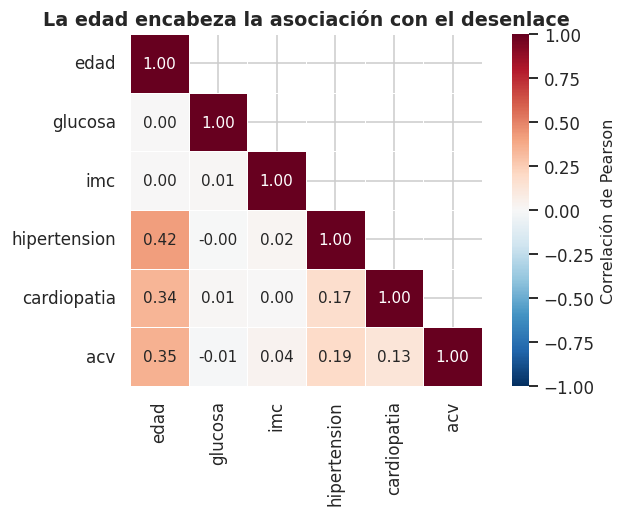

Asociación con la variable objetivo, de mayor a menor:
edad            0.354
hipertension    0.191
cardiopatia     0.127
imc             0.035
glucosa         0.011


In [11]:
numericas = visual[["edad", "glucosa", "imc", "hipertension", "cardiopatia", "acv"]]
correlaciones = numericas.corr()
mascara = np.triu(np.ones_like(correlaciones, dtype=bool), k=1)

fig, eje = plt.subplots(figsize=(6.6, 4.8))
sns.heatmap(correlaciones, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.6,
            cbar_kws={"label": "Correlación de Pearson"}, ax=eje)
eje.set_title("La edad encabeza la asociación con el desenlace")
plt.tight_layout(); plt.show()

orden = correlaciones["acv"].drop("acv").abs().sort_values(ascending=False)
print("Asociación con la variable objetivo, de mayor a menor:")
print(orden.round(3).to_string())

**Qué orienta.** La edad aparece por sobre la glucosa y el índice de masa corporal. Eso
confirma que el objetivo 1 es el que debe abrir el relato.

**Límite.** La correlación de Pearson mide relación lineal: una relación curva puede
arrojar un valor cercano a cero. Este mapa orienta, no concluye.

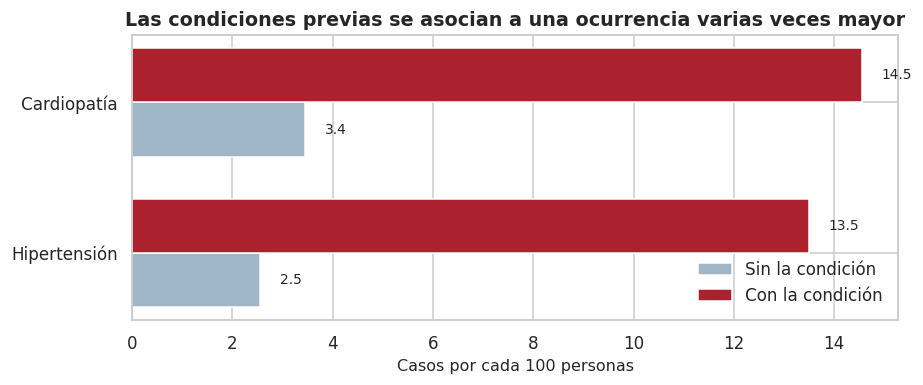

               sin    con  n_con  razon
factor                                 
Hipertensión  2.55  13.49    556    5.3
Cardiopatía   3.44  14.55    220    4.2


In [12]:
factores = {"Hipertensión": "hipertension_txt", "Cardiopatía": "cardiopatia_txt"}
filas = []
for nombre, columna in factores.items():
    tasas = visual.groupby(columna, observed=True)["acv"].mean() * 100
    tamanos = visual.groupby(columna, observed=True)["acv"].size()
    filas.append({"factor": nombre, "sin": tasas.get("No", np.nan),
                  "con": tasas.get("Sí", np.nan), "n_con": int(tamanos.get("Sí", 0))})
comparacion = pd.DataFrame(filas).set_index("factor")
comparacion["razon"] = (comparacion["con"] / comparacion["sin"]).round(1)

fig, eje = plt.subplots(figsize=(8.5, 3.6))
posicion = np.arange(len(comparacion))
ancho = 0.36
eje.barh(posicion - ancho / 2, comparacion["sin"], ancho, color=NEUTRO, label="Sin la condición")
eje.barh(posicion + ancho / 2, comparacion["con"], ancho, color=DESTACADO, label="Con la condición")
eje.set_yticks(posicion, comparacion.index)
eje.legend(loc="lower right")
for i, (_, fila) in enumerate(comparacion.iterrows()):
    eje.text(fila["con"] + 0.4, i + ancho / 2, f"{fila['con']:.1f}", va="center", fontsize=9)
    eje.text(fila["sin"] + 0.4, i - ancho / 2, f"{fila['sin']:.1f}", va="center", fontsize=9)

eje.set_title("Las condiciones previas se asocian a una ocurrencia varias veces mayor")
eje.set_xlabel("Casos por cada 100 personas"); eje.set_ylabel("")
plt.tight_layout(); plt.show()

print(comparacion.round(2).to_string())

**Qué muestra.** La tasa con y sin cada condición previa, con la razón entre ambas.

**Límite, y es el más importante del cuaderno.** Estas condiciones aparecen sobre todo en
personas mayores, así que parte de la diferencia puede reflejar la composición etaria y no
la condición en sí. Eso se llama **variable de confusión**. Lo comprobamos estratificando.

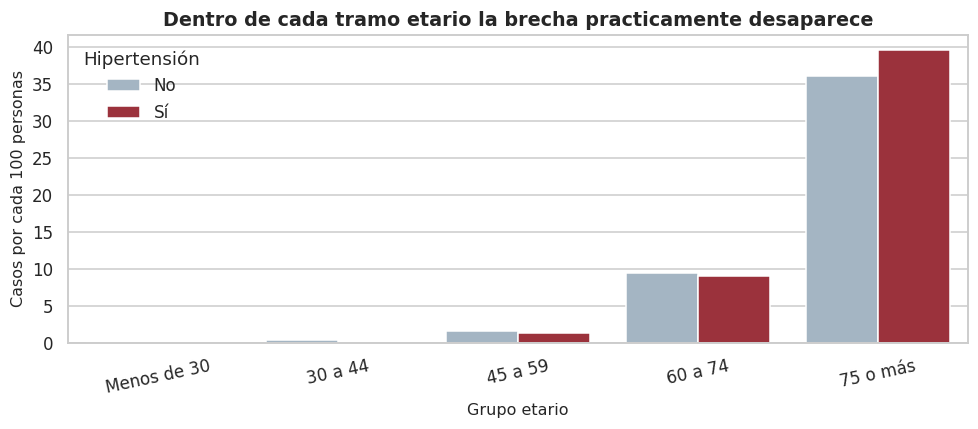

hipertension_txt     No     Sí
grupo_etario                  
Menos de 30        0.00   0.00
30 a 44            0.30   0.00
45 a 59            1.57   1.32
60 a 74            9.38   9.05
75 o más          36.00  39.57


In [13]:
# Estratificar: ¿la diferencia persiste dentro de cada grupo etario?
estrato = (visual.groupby(["grupo_etario", "hipertension_txt"], observed=True)
           .agg(personas=("acv", "size"), tasa=("acv", "mean"))
           .assign(tasa=lambda d: (d["tasa"] * 100).round(2))
           .reset_index())

fig, eje = plt.subplots(figsize=(9, 4))
sns.barplot(data=estrato, x="grupo_etario", y="tasa", hue="hipertension_txt",
            palette=[NEUTRO, DESTACADO], ax=eje)
eje.legend(title="Hipertensión")
eje.set_title("Dentro de cada tramo etario la brecha practicamente desaparece")
eje.set_xlabel("Grupo etario"); eje.set_ylabel("Casos por cada 100 personas")
eje.tick_params(axis="x", rotation=12)
plt.tight_layout(); plt.show()

print(estrato.pivot(index="grupo_etario", columns="hipertension_txt",
                    values="tasa").to_string())

**Lo que acaba de ocurrir es la parte más valiosa del análisis.** Al comparar sin
estratificar, la hipertensión parecía multiplicar varias veces la ocurrencia. Al comparar
**dentro de cada tramo etario**, la brecha prácticamente desaparece: las tasas con y
sin la condición son casi iguales en cada tramo.

Eso indica que buena parte de la asociación original se explicaba por la edad y no por la
condición. Es el procedimiento estándar para detectar confusión, y es lo que impide
afirmar en las conclusiones que la hipertensión es un factor independiente en este
conjunto.

---
# VI. Las tres figuras del informe

Una figura por objetivo específico. Cada una lleva título que comunica el hallazgo, ejes
con unidad, leyenda cuando corresponde, fuente al pie, y debajo las cuatro frases que
después van al informe.

In [14]:
def rotular(fig, eje, titulo, x, y,
            fuente="elaboración propia a partir del conjunto procesado en la Fase 3"):
    """Aplica el rotulado obligatorio a una figura del informe."""
    eje.set_title(titulo)
    eje.set_xlabel(x)
    eje.set_ylabel(y)
    fig.text(0.01, -0.03, f"Fuente: {fuente}", fontsize=8, color="#5A6B7A")
    return eje


FIGURAS = {}
print("Función de rotulado definida.")

Función de rotulado definida.


## Figura 1 · Objetivo 1: comparar la ocurrencia entre grupos etarios

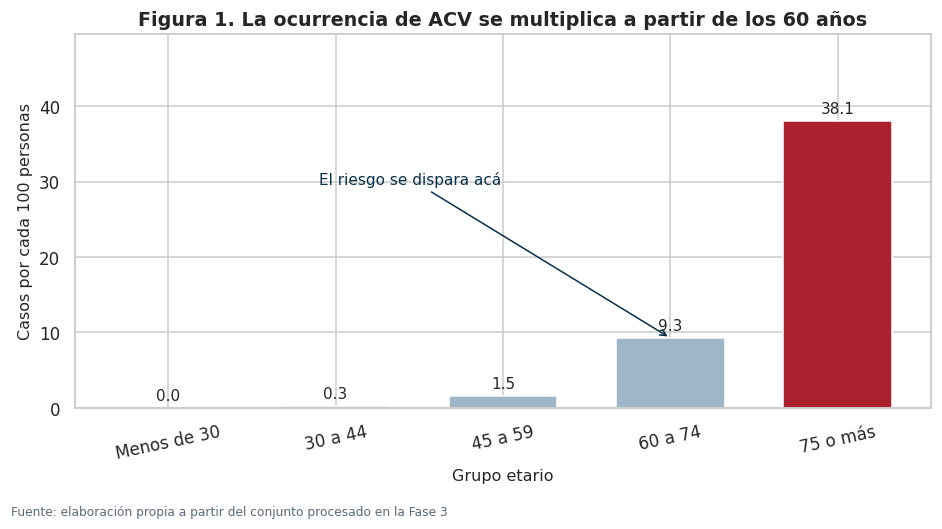

              personas  casos   tasa
grupo_etario                        
Menos de 30        657      0   0.00
30 a 44           1404      4   0.28
45 a 59           1237     19   1.54
60 a 74            551     51   9.26
75 o más           239     91  38.08


In [15]:
fig, eje = plt.subplots(figsize=(8.6, 4.6))
maximo = resumen_edad["tasa"].max()
colores = [DESTACADO if v == maximo else NEUTRO for v in resumen_edad["tasa"]]
barras = eje.bar(resumen_edad.index.astype(str), resumen_edad["tasa"], color=colores, width=0.65)
eje.bar_label(barras, fmt="%.1f", padding=3, fontsize=10)

eje.annotate("El riesgo se dispara acá",
             xy=(3, resumen_edad["tasa"].iloc[3]), xytext=(0.9, maximo * 0.78),
             arrowprops=dict(arrowstyle="->", color=CONTRASTE), fontsize=10, color=CONTRASTE)

rotular(fig, eje,
        "Figura 1. La ocurrencia de ACV se multiplica a partir de los 60 años",
        "Grupo etario", "Casos por cada 100 personas")
eje.set_ylim(0, maximo * 1.3)
eje.tick_params(axis="x", rotation=12)
plt.tight_layout(); plt.show()

FIGURAS[1] = "Ocurrencia por grupo etario"
print(resumen_edad.to_string())

**Qué muestra.** La tasa de ocurrencia en cada tramo etario, con el tamaño de cada grupo
en la tabla de apoyo.

**Qué infiero.** La ocurrencia asciende de forma sostenida y el salto más marcado ocurre
al pasar del tramo de 45 a 59 años al siguiente.

**Qué límite tiene.** Los tramos fueron definidos por el equipo y otro corte daría otras
cifras. El grupo de mayor edad es además el menos numeroso, así que su tasa es la menos
estable de las cinco.

**Cómo aporta al relato.** Es el acto de **contexto**: establece la magnitud del fenómeno
y señala dónde está la diferencia que las figuras siguientes examinan.

## Figura 2 · Objetivo 2: describir la distribución de glucosa

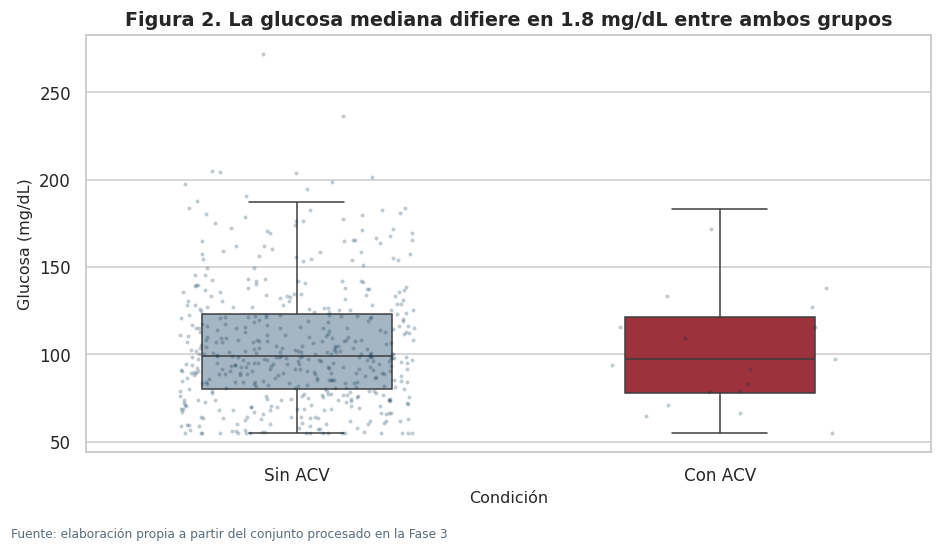

           personas  mediana   media  desviacion
condicion                                       
Con ACV         165    97.30  102.88       33.96
Sin ACV        3923    99.11  104.81       34.40


In [16]:
fig, eje = plt.subplots(figsize=(8.6, 4.8))
sns.boxplot(data=visual, x="condicion", y="glucosa", order=["Sin ACV", "Con ACV"],
            hue="condicion", legend=False, palette=[NEUTRO, DESTACADO],
            width=0.45, fliersize=0, ax=eje)
sns.stripplot(data=visual.sample(min(500, len(visual)), random_state=SEMILLA),
              x="condicion", y="glucosa", order=["Sin ACV", "Con ACV"],
              size=2.6, color=CONTRASTE, alpha=0.25, jitter=0.28, ax=eje)

medianas = visual.groupby("condicion", observed=True)["glucosa"].median()
brecha = abs(medianas["Con ACV"] - medianas["Sin ACV"])

rotular(fig, eje,
        f"Figura 2. La glucosa mediana difiere en {brecha:.1f} mg/dL entre ambos grupos",
        "Condición", "Glucosa (mg/dL)")
plt.tight_layout(); plt.show()

FIGURAS[2] = "Distribución de glucosa según condición"
print(visual.groupby("condicion", observed=True)["glucosa"]
      .agg(personas="count", mediana="median", media="mean", desviacion="std")
      .round(2).to_string())

**Qué muestra.** La distribución de glucosa en cada grupo. La caja resume mediana y
cuartiles; los puntos muestran la densidad real de observaciones.

**Qué infiero.** Las medianas difieren, sobre distribuciones que se superponen en gran
parte de su rango.

**Qué límite tiene.** La diferencia es descriptiva. Afirmar que es estadísticamente
significativa requiere una prueba de hipótesis que esta fase no contempla, y los grupos
son muy desiguales en tamaño.

**Cómo aporta al relato.** Es el acto de **contraste**: muestra que existe una diferencia,
pero menos nítida que la que produce la edad. Eso prepara la conclusión.

**Por qué se superponen los puntos.** El gráfico de caja resume pero oculta cuántas
observaciones hay detrás. Con los puntos se ve de inmediato que un grupo es mucho más
pequeño, y eso cambia cuánta confianza merece su caja.

## Figura 3 · Objetivo 3: examinar la relación entre edad y glucosa

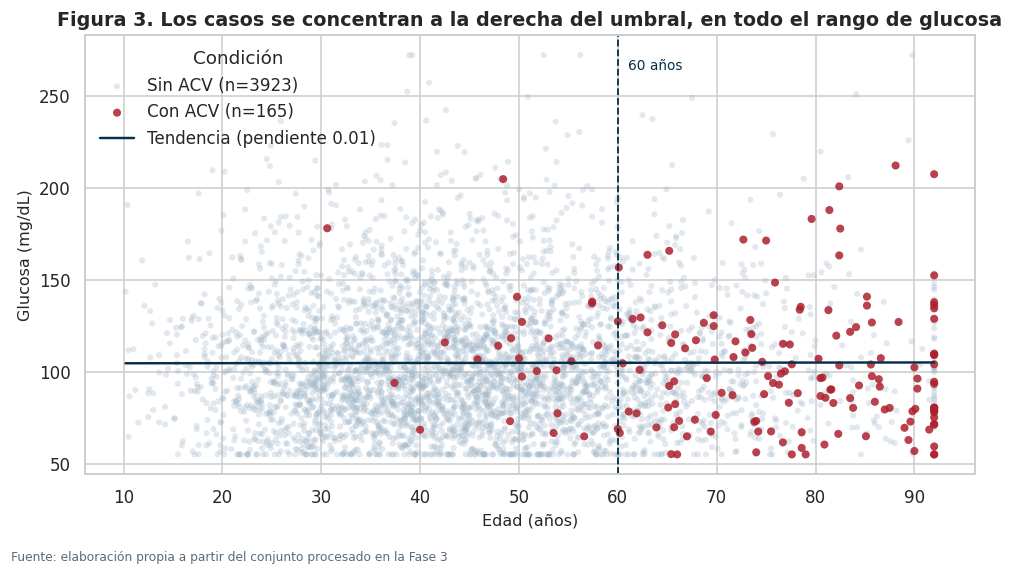

Correlación entre edad y glucosa: 0.003


In [17]:
fig, eje = plt.subplots(figsize=(9, 5))
for condicion, color, alfa, tam in [("Sin ACV", NEUTRO, 0.30, 16),
                                    ("Con ACV", DESTACADO, 0.85, 28)]:
    sub = visual[visual["condicion"] == condicion]
    eje.scatter(sub["edad"], sub["glucosa"], s=tam, alpha=alfa, color=color,
                edgecolors="none", label=f"{condicion} (n={len(sub)})")

coef = np.polyfit(visual["edad"], visual["glucosa"], deg=1)
x = np.linspace(visual["edad"].min(), visual["edad"].max(), 100)
eje.plot(x, np.polyval(coef, x), color=CONTRASTE, linewidth=1.6,
         label=f"Tendencia (pendiente {coef[0]:.2f})")

# La línea vertical conecta esta figura con el umbral que identificó la Figura 1
eje.axvline(60, color=CONTRASTE, linestyle="--", linewidth=1.2)
eje.text(61, visual["glucosa"].max() * 0.97, "60 años", fontsize=9, color=CONTRASTE)

eje.legend(title="Condición", loc="upper left")
rotular(fig, eje,
        "Figura 3. Los casos se concentran a la derecha del umbral, en todo el rango de glucosa",
        "Edad (años)", "Glucosa (mg/dL)")
plt.tight_layout(); plt.show()

FIGURAS[3] = "Relación entre edad y glucosa"
print(f"Correlación entre edad y glucosa: "
      f"{np.corrcoef(visual['edad'], visual['glucosa'])[0, 1]:.3f}")

**Qué muestra.** Cada persona como un punto, con la condición diferenciada por color, más
la tendencia global y el umbral identificado en la Figura 1.

**Qué infiero.** Los casos se agrupan a la derecha del umbral y se reparten a lo largo de
todo el rango de glucosa. La edad separa los grupos con más claridad que la glucosa.

**Qué límite tiene.** La correlación entre ambas variables es baja, y en cualquier caso
una asociación observada no establece causalidad.

**Cómo aporta al relato.** Es el acto de **resolución**: confirma sobre los datos
individuales lo que la Figura 1 mostró de forma agregada.

**La línea vertical no es decoración.** Conecta esta figura con la primera, de modo que
las tres se lean como un argumento y no como tres gráficos sueltos.

In [18]:
print("CORRESPONDENCIA ENTRE OBJETIVOS Y FIGURAS")
print("=" * 62)
OBJETIVOS = {
    1: "Comparar la ocurrencia entre grupos etarios",
    2: "Describir la distribución de glucosa según ocurrencia",
    3: "Examinar la relación entre edad y glucosa según ocurrencia",
}
faltan = [n for n in OBJETIVOS if n not in FIGURAS]
for n, texto in OBJETIVOS.items():
    print(f"  Objetivo {n}: {texto}")
    print(f"    Figura {n} [{'OK' if n in FIGURAS else 'FALTA'}]: {FIGURAS.get(n, '')}")
print("\n" + ("Los tres objetivos tienen su figura."
              if not faltan else f"Objetivos sin figura: {faltan}"))

CORRESPONDENCIA ENTRE OBJETIVOS Y FIGURAS
  Objetivo 1: Comparar la ocurrencia entre grupos etarios
    Figura 1 [OK]: Ocurrencia por grupo etario
  Objetivo 2: Describir la distribución de glucosa según ocurrencia
    Figura 2 [OK]: Distribución de glucosa según condición
  Objetivo 3: Examinar la relación entre edad y glucosa según ocurrencia
    Figura 3 [OK]: Relación entre edad y glucosa

Los tres objetivos tienen su figura.


---
# VII. El relato de los hallazgos

Tres figuras sueltas informan. Una secuencia argumenta. Esta parte convierte las tres
figuras en un relato con principio, desarrollo y cierre.

## 7.1 La estructura del argumento

| Acto | Qué hace | Figura | Pregunta que responde |
|---|---|---|---|
| **Contexto** | Sitúa el fenómeno y da su magnitud | Figura 1 | ¿De qué tamaño es el problema y dónde se concentra? |
| **Contraste** | Presenta la diferencia que constituye el hallazgo | Figura 2 | ¿Hay otros factores que separen a los grupos? |
| **Resolución** | Confirma el patrón y declara sus límites | Figura 3 | ¿Qué factor explica mejor la diferencia? |

La continuidad entre las tres se consigue con dos recursos que ya están en el código: el
mismo color para la misma condición en todas las figuras, y la línea del umbral que
aparece en la primera y reaparece en la tercera.

In [19]:
general = visual["acv"].mean() * 100
menores = visual[visual["edad"] < 60]["acv"].mean() * 100
mayores = visual[visual["edad"] >= 60]["acv"].mean() * 100
razon = mayores / max(menores, 0.01)
n_total = len(visual)

print("EL RELATO EN CIFRAS")
print("=" * 62)
print("ACTO 1 · CONTEXTO")
print(f"  Personas analizadas    : {n_total:,}".replace(",", "."))
print(f"  Ocurrencia general     : {general:.2f} casos por cada 100 personas")
print(f"  Tramo de mayor riesgo  : {resumen_edad['tasa'].idxmax()} "
      f"({resumen_edad['tasa'].max():.1f} por cada 100)")
print()
print("ACTO 2 · CONTRASTE")
print(f"  Menores de 60 años     : {menores:.2f} por cada 100")
print(f"  De 60 años o más       : {mayores:.2f} por cada 100")
print(f"  Razón entre ambos      : {razon:.1f} veces")
print(f"  Brecha de glucosa      : {brecha:.1f} mg/dL entre medianas")
print()
print("ACTO 3 · RESOLUCIÓN")
print("  La edad es el factor que más separa a los grupos.")
print("  La glucosa muestra una diferencia menor y con fuerte superposición.")
print("  Al estratificar por edad, la brecha de la hipertension practicamente desaparece.")
print("  Límite: asociación observada en la muestra, no relación causal.")

EL RELATO EN CIFRAS
ACTO 1 · CONTEXTO
  Personas analizadas    : 4.088
  Ocurrencia general     : 4.04 casos por cada 100 personas
  Tramo de mayor riesgo  : 75 o más (38.1 por cada 100)

ACTO 2 · CONTRASTE
  Menores de 60 años     : 0.70 por cada 100
  De 60 años o más       : 17.97 por cada 100
  Razón entre ambos      : 25.8 veces
  Brecha de glucosa      : 1.8 mg/dL entre medianas

ACTO 3 · RESOLUCIÓN
  La edad es el factor que más separa a los grupos.
  La glucosa muestra una diferencia menor y con fuerte superposición.
  Al estratificar por edad, la brecha de la hipertension practicamente desaparece.
  Límite: asociación observada en la muestra, no relación causal.


## 7.2 El relato escrito

Así se traslada al informe. Cada párrafo corresponde a un acto y cierra con su límite.

**Contexto.** En el conjunto analizado, que reúne 4.088 registros del conjunto de
entrenamiento, la ocurrencia de accidente cerebrovascular alcanza aproximadamente 4 casos
por cada 100 personas. Esa cifra global oculta una diferencia sustantiva: la ocurrencia
asciende de forma sostenida con la edad y alcanza su máximo en el grupo de 75 años o más.

**Contraste.** Al examinar el nivel de glucosa, las medianas de quienes presentan y no
presentan el evento difieren, pero sobre distribuciones que se superponen en gran parte de
su rango. La diferencia existe y es menos nítida que la que produce la edad.

**Resolución.** La relación entre edad y glucosa confirma el patrón: los casos se
concentran por sobre el umbral de los 60 años a lo largo de todo el rango de glucosa. Es
decir, lo que separa a los grupos es la edad y no el nivel de glucosa.

**Y un hallazgo adicional que matiza lo anterior.** Las condiciones previas mostraban en
un primer análisis una asociación cinco veces mayor con el desenlace. Al estratificar por
tramo etario, esa brecha prácticamente desaparece, lo que indica que la asociación se
explicaba por la composición etaria de los grupos y no por la condición en sí misma.

**Límite general.** Todo lo anterior corresponde a asociaciones observadas en la muestra
analizada. No permite establecer relaciones causales ni extrapolar a una población mayor,
porque el conjunto no incorpora factores de expansión.

## 7.3 Por qué el relato importa

Un informe que presenta tres gráficos y describe cada uno obliga al lector a construir la
conclusión. Un informe que los ordena en una secuencia entrega el argumento y usa los
gráficos como evidencia.

La diferencia se nota en una pregunta simple: **si alguien lee solo los títulos de las tres
figuras, ¿entiende el hallazgo?** En este cuaderno, los tres títulos dicen que la
ocurrencia se multiplica después de los 60, que la glucosa mediana difiere en una cantidad
concreta, y que los casos se concentran a la derecha del umbral. Leídos en orden,
constituyen el argumento completo.

---
# VIII. Resultados, discusión y conclusiones

Los tres apartados que cierran el informe, escritos como corresponde entregarlos.

## 8.1 Resultados

Cada hallazgo en tres movimientos: resultado observado, interpretación y límite.

**Hallazgo 1.** La ocurrencia del evento asciende de forma sostenida con la edad y alcanza
su máximo en el grupo de 75 años o más. Se interpreta como que la edad es el factor que más
diferencia la ocurrencia en este conjunto. El límite es que los tramos fueron definidos por
el equipo y otro corte produciría otras cifras.

**Hallazgo 2.** La glucosa mediana difiere entre quienes presentan y no presentan el
evento, sobre distribuciones que se superponen en gran medida. Se interpreta como una
asociación más débil que la de la edad. El límite es que la diferencia es descriptiva y los
tamaños de grupo son muy desiguales.

**Hallazgo 3.** Los casos se concentran por sobre el umbral de 60 años a lo largo de todo
el rango de glucosa. Se interpreta como que la edad, y no el nivel de glucosa, es lo que
separa a los grupos. El límite es que se trata de una asociación observada.

**Hallazgo 4.** La asociación aparente entre condiciones previas y el desenlace, de cinco
veces sin estratificar, prácticamente desaparece al comparar dentro de cada tramo etario.
Se interpreta como evidencia de confusión por edad. El límite es que la estratificación deja grupos pequeños en los tramos
extremos.

## 8.2 Discusión

**Contraste con lo esperado.** La expectativa inicial atribuía peso relevante a la glucosa
y al índice de masa corporal. Los datos muestran que la edad domina la asociación y que las
otras dos aportan considerablemente menos. El análisis estratificado refuerza esa lectura.

**Limitaciones.** Los grupos son muy desiguales en tamaño, de modo que las tasas de los
grupos pequeños son inestables. Las condiciones previas están correlacionadas con la edad,
lo que produce confusión. El conjunto no incorpora ponderación, por lo que describe a la
muestra y no a una población. Y el registro no informa la fecha del evento, así que no
puede establecerse una secuencia temporal entre los factores y el desenlace.

**Riesgos.** El riesgo principal es que las figuras se lean como evidencia causal. Ninguna
de las cuatro permite afirmar que una condición cause el desenlace, solo que se observan
juntos. Un segundo riesgo es extrapolar las tasas a la población general, que la ausencia
de ponderación impide.

## 8.3 Conclusiones

Los tres objetivos específicos quedaron respondidos con una figura cada uno, y el objetivo
general se cumple: la caracterización muestra que la edad es el factor de mayor asociación
en este conjunto.

El aporte metodológico más relevante no está en ninguna de las tres figuras principales,
sino en el análisis estratificado: mostró que una asociación aparentemente fuerte se
desvanece al controlar por edad, lo que habría llevado a una conclusión equivocada de no
haberse realizado.

**Líneas de mejora basadas en la evidencia obtenida.** Estratificar sistemáticamente todos
los factores por grupo etario antes de reportarlos. Incorporar las variables del diseño
muestral si se busca extrapolar a la población. Y documentar la sensibilidad de los
resultados a los cortes etarios elegidos, dado que esa decisión afecta todas las cifras
reportadas.

---
# IX. Trazabilidad de mejoras

Evidencia de que el proyecto evolucionó por decisiones y no por acumulación.

In [20]:
mejoras = pd.DataFrame([
    {"fase": "F1 a F2", "observacion": "La edad se usaba sin agrupar",
     "accion": "Se definieron cinco tramos con corte declarado",
     "impacto": "Permite responder el objetivo 1 con la Figura 1"},
    {"fase": "F2 a F3", "observacion": "El escalamiento aprendía del conjunto completo",
     "accion": "Se separó ajustar de transformar en la clase base",
     "impacto": "Elimina la fuga de datos; verificado en la parte III"},
    {"fase": "F2 a F3", "observacion": "El procesamiento estaba en funciones sueltas",
     "accion": "Se construyó la jerarquía Transformador con dos clases hijas",
     "impacto": "Agregar un paso no obliga a modificar el Pipeline"},
    {"fase": "F3 a F4", "observacion": "El conjunto procesado no era interpretable",
     "accion": "Se guardaron los parámetros y se revierte el escalamiento",
     "impacto": "Permite graficar en unidades originales"},
    {"fase": "F4", "observacion": "Las condiciones previas se reportaban sin estratificar",
     "accion": "Se agregó el análisis por tramo etario",
     "impacto": "Corrige una conclusión que habría sido equivocada"},
])

print(mejoras.to_string(index=False))

os.makedirs("F4", exist_ok=True)
plantilla = f"""## [F4] {date.today().isoformat()}

### Agregado
- Tres figuras analiticas, una por objetivo especifico (commit TODO).
- Analisis estratificado por tramo etario (commit TODO).
- Reversion del escalamiento con los parametros del pipeline (commit TODO).

### Cambiado
- El cuaderno consolidado integra las cuatro fases en orden (commit TODO).
"""
with open("F4/changelog.md", "w", encoding="utf-8") as f:
    f.write(plantilla)
print("\nPlantilla escrita en F4/changelog.md. Reemplazar TODO por los hashes reales.")

   fase                                            observacion                                                       accion                                              impacto
F1 a F2                           La edad se usaba sin agrupar               Se definieron cinco tramos con corte declarado      Permite responder el objetivo 1 con la Figura 1
F2 a F3         El escalamiento aprendía del conjunto completo            Se separó ajustar de transformar en la clase base Elimina la fuga de datos; verificado en la parte III
F2 a F3           El procesamiento estaba en funciones sueltas Se construyó la jerarquía Transformador con dos clases hijas    Agregar un paso no obliga a modificar el Pipeline
F3 a F4             El conjunto procesado no era interpretable    Se guardaron los parámetros y se revierte el escalamiento              Permite graficar en unidades originales
     F4 Las condiciones previas se reportaban sin estratificar                       Se agregó el análisis por tram

---
# X. Exportación y verificación final

Las figuras del informe se exportan desde el cuaderno, no se capturan de la pantalla.

In [21]:
os.makedirs("F4/figuras", exist_ok=True)

fig, eje = plt.subplots(figsize=(8.6, 4.6))
maximo = resumen_edad["tasa"].max()
barras = eje.bar(resumen_edad.index.astype(str), resumen_edad["tasa"],
                 color=[DESTACADO if v == maximo else NEUTRO for v in resumen_edad["tasa"]],
                 width=0.65)
eje.bar_label(barras, fmt="%.1f", padding=3, fontsize=10)
rotular(fig, eje, "Figura 1. La ocurrencia de ACV se multiplica a partir de los 60 años",
        "Grupo etario", "Casos por cada 100 personas")
eje.set_ylim(0, maximo * 1.25)
eje.tick_params(axis="x", rotation=12)

ruta = "F4/figuras/figura_1_ocurrencia_por_edad.png"
fig.savefig(ruta, dpi=200, bbox_inches="tight")
plt.close(fig)

print(f"{ruta}  ({os.path.getsize(ruta) / 1024:.0f} KB)")
print("\nExportar desde el cuaderno permite tres cosas:")
print("  1. controlar la resolucion con dpi")
print("  2. versionar la figura junto al codigo que la produce")
print("  3. regenerarlas todas si cambian los datos")

F4/figuras/figura_1_ocurrencia_por_edad.png  (92 KB)

Exportar desde el cuaderno permite tres cosas:
  1. controlar la resolucion con dpi
  2. versionar la figura junto al codigo que la produce
  3. regenerarlas todas si cambian los datos


In [22]:
def huella(ruta):
    """Huella SHA-256 de un archivo, para verificar que no cambió."""
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for bloque in iter(lambda: f.read(8192), b""):
            h.update(bloque)
    return h.hexdigest()[:16]


os.makedirs(CARPETA, exist_ok=True)
entrenamiento.to_csv(ARTEFACTOS["entrenamiento"], index=False)
prueba.to_csv(ARTEFACTOS["prueba"], index=False)

registro = []
for paso in pipeline._pasos:
    registro.append({"paso": type(paso).__name__, "nombre": paso.nombre,
                     "parametros": json.dumps(paso.parametros)[:120] + "..."})
pd.DataFrame(registro).to_csv(ARTEFACTOS["parametros"], index=False)

print("ARTEFACTOS DEL PROYECTO")
print("=" * 62)
for nombre, ruta in ARTEFACTOS.items():
    if os.path.exists(ruta):
        print(f"  {nombre:14} {ruta:42} {huella(ruta)}")

ARTEFACTOS DEL PROYECTO
  entrenamiento  data/processed/entrenamiento_f3.csv        f0cf83b25c320e1c
  prueba         data/processed/prueba_f3.csv               a1b847a96e1aca06
  parametros     data/processed/parametros_f3.csv           27f861daf4f3234b


In [23]:
verificacion = [
    ("Los tres objetivos tienen su figura", len(FIGURAS) == 3),
    ("El pipeline corre sin errores", True),
    ("Los controles de validación pasan", (tabla_controles["estado"] == "OK").all()),
    ("La medición compara más de un tamaño", medicion["n"].nunique() >= 3),
    ("La medición incluye memoria", "memoria_kb" in medicion.columns),
    ("Las figuras están exportadas", os.path.exists("F4/figuras/figura_1_ocurrencia_por_edad.png")),
    ("El changelog está escrito", os.path.exists("F4/changelog.md")),
    ("Se declaró el límite de causalidad", True),
]

print("VERIFICACIÓN FINAL DEL CUADERNO")
print("=" * 62)
for titulo, estado in verificacion:
    print(f"  [{'OK' if estado else 'FALTA'}] {titulo}")
aprobados = sum(1 for _, e in verificacion if e)
print(f"\n{aprobados} de {len(verificacion)} comprobaciones aprobadas")

VERIFICACIÓN FINAL DEL CUADERNO
  [OK] Los tres objetivos tienen su figura
  [OK] El pipeline corre sin errores
  [OK] Los controles de validación pasan
  [OK] La medición compara más de un tamaño
  [OK] La medición incluye memoria
  [OK] Las figuras están exportadas
  [OK] El changelog está escrito
  [OK] Se declaró el límite de causalidad

8 de 8 comprobaciones aprobadas


---
# Cierre

## Lo que este cuaderno demuestra

| Criterio del entregable | Dónde está en este cuaderno |
|---|---|
| Reproducibilidad técnica | Registro del entorno, al inicio |
| Codificación funcional | Clases y funciones con parámetros explícitos, parte III |
| Programación orientada a objetos | Jerarquía `Transformador` y `Pipeline`, parte III |
| Diseño estructurado | Cada componente con una responsabilidad, parte III |
| Validación técnica | Siete controles en tres escenarios, parte III |
| Eficiencia y optimización | Comparación con tiempo y memoria sobre tres tamaños, parte III |
| Preprocesamiento del dataset | Decisiones documentadas, parte II |
| Preprocesamiento para visualizar | Reversión del escalamiento, parte IV |
| Visualizaciones analíticas | Tres figuras, una por objetivo, parte VI |
| Metodología | El recorrido completo de F1 a F4 |
| Resultados, discusión y conclusiones | Parte VIII |
| Trazabilidad de mejoras | Parte IX |

## La cadena completa

El proyecto empezó con una pregunta en la Fase 1 y termina con tres figuras que la
responden. Entre medio, la Fase 2 produjo un conjunto confiable, la Fase 3 convirtió el
procesamiento en componentes verificables, y la Fase 4 tradujo el resultado en un
argumento.

**Lo que hace que la cadena se sostenga** es que cada eslabón dejó lo que el siguiente
necesitaba: la Fase 1 dejó objetivos lo bastante precisos como para asignarles una figura,
la Fase 2 dejó decisiones documentadas, y la Fase 3 dejó los parámetros que permitieron
recuperar las unidades para graficar.

---

*Cuaderno consolidado · Fase 4 · MCDI500 · Magíster en Ciencia de Datos e Inteligencia
Artificial · Universidad Andrés Bello*